## BÀI 6 (TRANG 27): PHÂN LỚP DỮ LIỆU NẤM (MUSHROOM CLASSIFICATION)
**Họ tên sinh viên:** Lương Thị Kim Ngân  
**MSSV:** 6451071049  
**Lớp:** CQ.64.CN.CNTT  
**Repository Github:** https://github.com/kimngan11/6451071049_Lab2  

Dữ liệu Mushroom chứa đặc điểm của nhiều loại nấm cùng với phân loại `class`: nấm độc (`p`: poisonous) hay ăn được (`e`: edible).  
Chia dữ liệu huấn luyện 70%, kiểm thử 30% bằng câu lệnh:  
`X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)`


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import tree, metrics
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split

print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049")
print("Đã import các thư viện thành công!")


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Đã import các thư viện thành công!


### Câu 4: Tách các cột dữ liệu thành hai phần
- `features`: Chứa các đặc điểm hình thái của nấm.
- `labels`: Chứa riêng thuộc tính quyết định `'class'`.


In [4]:
import pandas as pd

# Link bộ dữ liệu nấm trực tiếp từ kho chuẩn UCI
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/agaricus-lepiota.data"

# Danh sách 23 thuộc tính chuẩn (cột đầu tiên là class: 'e' ăn được, 'p' độc)
columns = [
    'class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor',
    'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color',
    'stalk-shape', 'stalk-root', 'stalk-surface-above-ring',
    'stalk-surface-below-ring', 'stalk-color-above-ring',
    'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number',
    'ring-type', 'spore-print-color', 'population', 'habitat'
]

# Tải và đọc trực tiếp từ mạng
df_mush = pd.read_csv(url, names=columns)

print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
print("Kích thước dữ liệu nấm ban đầu:", df_mush.shape)

features = df_mush.drop('class', axis=1)
labels = df_mush['class']

print("Kích thước features:", features.shape)
print("Kích thước labels:", labels.shape)
print("\nPhân bố các lớp (e: ăn được, p: nấm độc):")
print(labels.value_counts())

Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Kích thước dữ liệu nấm ban đầu: (8124, 23)
Kích thước features: (8124, 22)
Kích thước labels: (8124,)

Phân bố các lớp (e: ăn được, p: nấm độc):
class
e    4208
p    3916
Name: count, dtype: int64


### Câu 5: Chuyển đổi các cột không phải dạng số về dạng one-hot vector
Vì toàn bộ các đặc trưng của nấm đều là dạng chuỗi ký tự (categorical), ta dùng `pd.get_dummies()` để mã hóa toàn bộ `features`.


In [5]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
features_onehot = pd.get_dummies(features)

print("Kích thước dữ liệu sau khi mã hóa One-hot:", features_onehot.shape)
print(features_onehot.head())


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Kích thước dữ liệu sau khi mã hóa One-hot: (8124, 117)
   cap-shape_b  cap-shape_c  cap-shape_f  cap-shape_k  cap-shape_s  \
0        False        False        False        False        False   
1        False        False        False        False        False   
2         True        False        False        False        False   
3        False        False        False        False        False   
4        False        False        False        False        False   

   cap-shape_x  cap-surface_f  cap-surface_g  cap-surface_s  cap-surface_y  \
0         True          False          False           True          False   
1         True          False          False           True          False   
2        False          False          False           True          False   
3         True          False          False          False           True   
4         True          False          False           True          False   

   ...  p

### Câu 6: Tách dòng dữ liệu thành phần huấn luyện 70% và kiểm thử 30%
Sử dụng câu lệnh theo hướng dẫn:
`X_train, X_test, y_train, y_test = train_test_split(features_onehot, labels, test_size=0.3, random_state=42)`


In [6]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
X_train, X_test, y_train, y_test = train_test_split(features_onehot, labels, test_size=0.3, random_state=42)

print("Số lượng mẫu huấn luyện (Train 70%):", len(X_train))
print("Số lượng mẫu kiểm thử (Test 30%):", len(X_test))


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Số lượng mẫu huấn luyện (Train 70%): 5686
Số lượng mẫu kiểm thử (Test 30%): 2438


### Câu 7: Xây dựng cây quyết định ID3 (criterion='entropy')
Huấn luyện cây ID3, kiểm thử bằng ma trận nhầm lẫn và biểu diễn cây.


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Độ chính xác (Accuracy ID3): 1.0000 (100%!)

Báo cáo phân lớp (Classification Report):
              precision    recall  f1-score   support

           e       1.00      1.00      1.00      1257
           p       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438



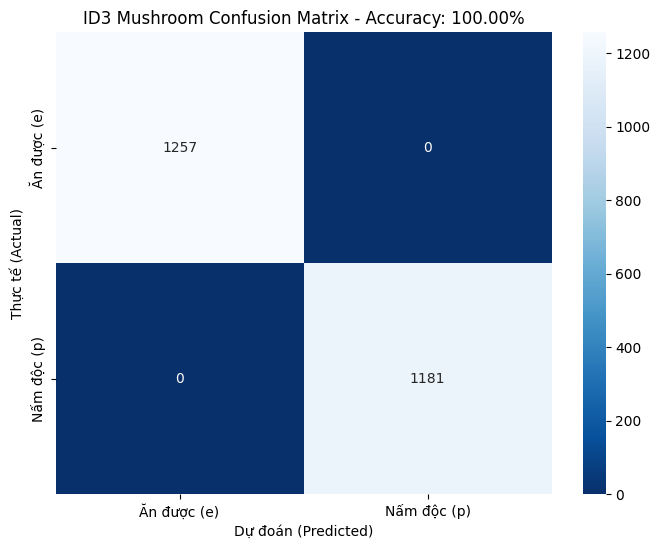

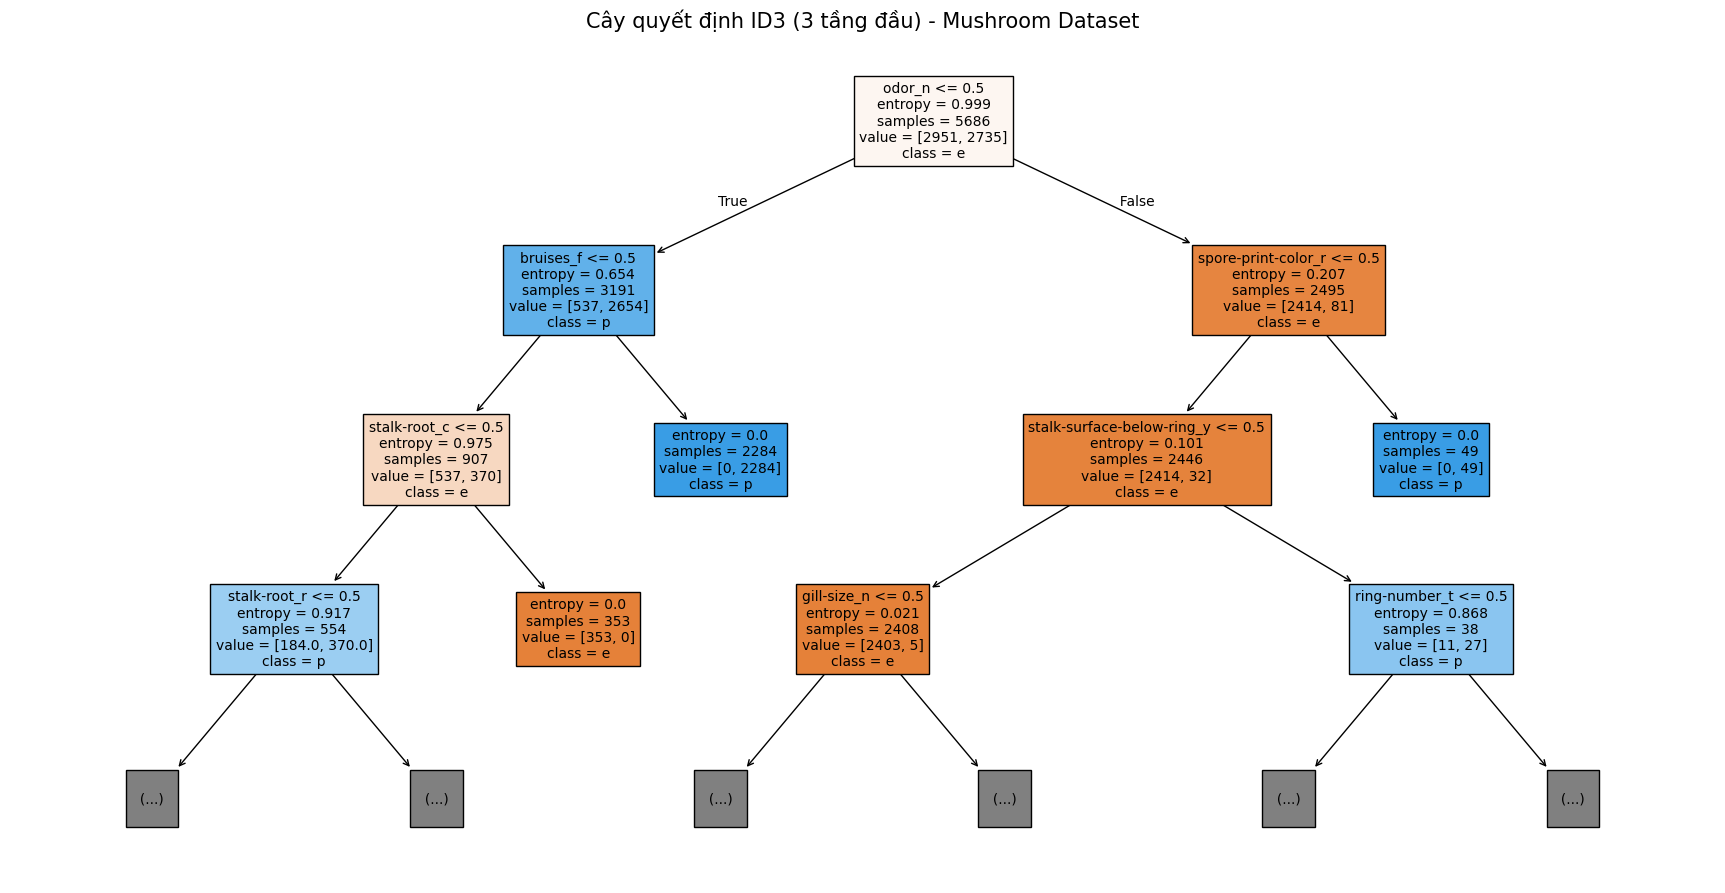

In [7]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
clf_id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=42)
clf_id3.fit(X_train, y_train)

id3_pred = clf_id3.predict(X_test)
id3_score = metrics.accuracy_score(y_test, id3_pred)

print(f"Độ chính xác (Accuracy ID3): {id3_score:.4f} (100%!)")
print("\nBáo cáo phân lớp (Classification Report):")
print(metrics.classification_report(y_test, id3_pred))

# Ma trận nhầm lẫn
id3_cm = metrics.confusion_matrix(y_test, id3_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(id3_cm, annot=True, fmt="d", cmap='Blues_r',
            xticklabels=['Ăn được (e)', 'Nấm độc (p)'],
            yticklabels=['Ăn được (e)', 'Nấm độc (p)'])
plt.title(f"ID3 Mushroom Confusion Matrix - Accuracy: {id3_score*100:.2f}%")
plt.xlabel("Dự đoán (Predicted)")
plt.ylabel("Thực tế (Actual)")
plt.show()

# Biểu diễn cây quyết định mẫu
fig, ax = plt.subplots(figsize=(22, 11))
tree.plot_tree(clf_id3, max_depth=3, feature_names=features_onehot.columns, class_names=['e', 'p'], filled=True, fontsize=10)
plt.title("Cây quyết định ID3 (3 tầng đầu) - Mushroom Dataset", fontsize=15)
plt.savefig('decision_tree_mush_id3.png', dpi=100, bbox_inches='tight')
plt.show()


### Câu 8: Xây dựng cây quyết định CART (criterion='gini')
Lặp lại yêu cầu 7 với cây CART.


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Độ chính xác (Accuracy CART): 1.0000 (100%!)

Báo cáo phân lớp (Classification Report):
              precision    recall  f1-score   support

           e       1.00      1.00      1.00      1257
           p       1.00      1.00      1.00      1181

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438



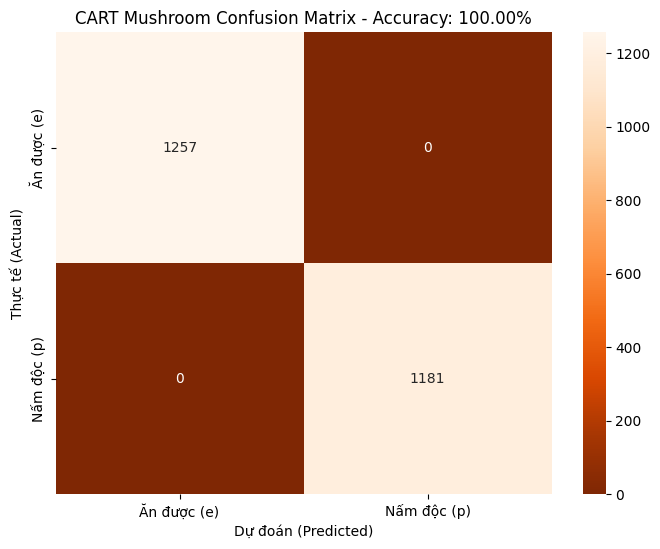

In [8]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=42)
clf_cart.fit(X_train, y_train)

cart_pred = clf_cart.predict(X_test)
cart_score = metrics.accuracy_score(y_test, cart_pred)

print(f"Độ chính xác (Accuracy CART): {cart_score:.4f} (100%!)")
print("\nBáo cáo phân lớp (Classification Report):")
print(metrics.classification_report(y_test, cart_pred))

# Ma trận nhầm lẫn
cart_cm = metrics.confusion_matrix(y_test, cart_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cart_cm, annot=True, fmt="d", cmap='Oranges_r',
            xticklabels=['Ăn được (e)', 'Nấm độc (p)'],
            yticklabels=['Ăn được (e)', 'Nấm độc (p)'])
plt.title(f"CART Mushroom Confusion Matrix - Accuracy: {cart_score*100:.2f}%")
plt.xlabel("Dự đoán (Predicted)")
plt.ylabel("Thực tế (Actual)")
plt.show()


### Câu 9: Xây dựng mô hình phân lớp bằng thuật toán Naïve Bayes
Sử dụng GaussianNB để phân lớp dữ liệu nấm.


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Độ chính xác (Accuracy Naive Bayes): 0.9643

Báo cáo phân lớp (Classification Report):
              precision    recall  f1-score   support

           e       1.00      0.93      0.96      1257
           p       0.93      1.00      0.96      1181

    accuracy                           0.96      2438
   macro avg       0.97      0.97      0.96      2438
weighted avg       0.97      0.96      0.96      2438



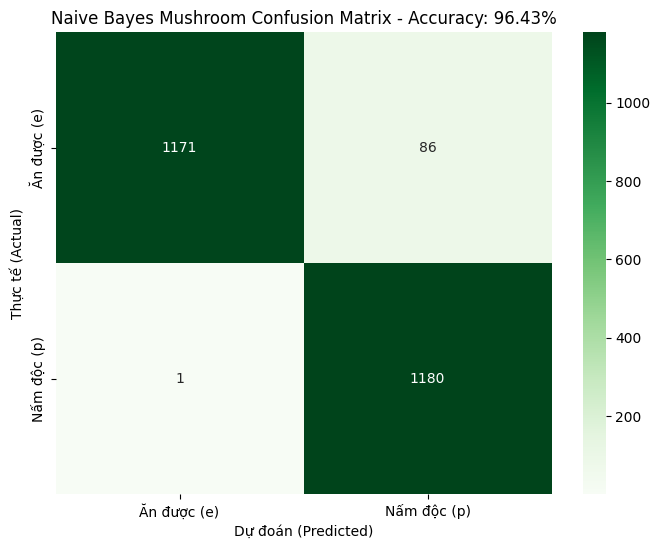

In [9]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
gnb = GaussianNB()
nb_pred = gnb.fit(X_train, y_train).predict(X_test)
nb_score = metrics.accuracy_score(y_test, nb_pred)

print(f"Độ chính xác (Accuracy Naive Bayes): {nb_score:.4f}")
print("\nBáo cáo phân lớp (Classification Report):")
print(metrics.classification_report(y_test, nb_pred))

# Ma trận nhầm lẫn
nb_cm = metrics.confusion_matrix(y_test, nb_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(nb_cm, annot=True, fmt="d", cmap='Greens',
            xticklabels=['Ăn được (e)', 'Nấm độc (p)'],
            yticklabels=['Ăn được (e)', 'Nấm độc (p)'])
plt.title(f"Naive Bayes Mushroom Confusion Matrix - Accuracy: {nb_score*100:.2f}%")
plt.xlabel("Dự đoán (Predicted)")
plt.ylabel("Thực tế (Actual)")
plt.show()


### Câu 10: So sánh kết quả của các mô hình trên dữ liệu Mushroom


In [11]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
comp_mush = pd.DataFrame({
    'Mô hình': ['ID3 (Entropy)', 'CART (Gini)', 'Naïve Bayes (GaussianNB)'],
    'Accuracy': [id3_score, cart_score, nb_score],
    'Precision (Nấm độc)': [
        metrics.precision_score(y_test, id3_pred, pos_label='p'),
        metrics.precision_score(y_test, cart_pred, pos_label='p'),
        metrics.precision_score(y_test, nb_pred, pos_label='p')
    ],
    'Recall (Nấm độc)': [
        metrics.recall_score(y_test, id3_pred, pos_label='p'),
        metrics.recall_score(y_test, cart_pred, pos_label='p'),
        metrics.recall_score(y_test, nb_pred, pos_label='p')
    ],
    'F1-score (Nấm độc)': [
        metrics.f1_score(y_test, id3_pred, pos_label='p'),
        metrics.f1_score(y_test, cart_pred, pos_label='p'),
        metrics.f1_score(y_test, nb_pred, pos_label='p')
    ]
})
print("BẢNG TỔNG HỢP HIỆU NĂNG TRÊN TẬP DỮ LIỆU MUSHROOM:")
print(comp_mush.to_string(index=False))


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
BẢNG TỔNG HỢP HIỆU NĂNG TRÊN TẬP DỮ LIỆU MUSHROOM:
                 Mô hình  Accuracy  Precision (Nấm độc)  Recall (Nấm độc)  F1-score (Nấm độc)
           ID3 (Entropy)  1.000000              1.00000          1.000000            1.000000
             CART (Gini)  1.000000              1.00000          1.000000            1.000000
Naïve Bayes (GaussianNB)  0.964315              0.93207          0.999153            0.964446
